**Live Demo (Streamlit Cloud):** https://YOUR-APP-NAME.streamlit.app  *(replace this with your own deployment link after Step 10)*

# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
Any Python 3.10 - 3.12 should work.

### 2. Create and activate a virtual environment
**Windows:** `python -m venv venv` then `venv\Scripts\activate.bat` (PowerShell: `venv\Scripts\Activate.ps1`)

**macOS / Linux:** `python3 -m venv venv` then `source venv/bin/activate`

### 3. Install the required packages
```
pip install -r requirements-notebook.txt
```

### 4. Register the virtual environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=heart-venv --display-name "Python (heart-venv)"
```

### 5. Launch Jupyter Notebook and run everything
```
jupyter notebook
```
Open this `.ipynb`, select the **Python (heart-venv)** kernel, then **Kernel -> Restart & Run All**.

The folder must contain the dataset file `processed.cleveland.data` (from the UCI repository).

---

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from four simple attributes of the patient.
##### **Application** An educational example of an end-to-end ML system (data collection -> deployment) on structured data. It is **not** a medical tool and must not be used for real diagnosis.

**Dataset:** Heart Disease dataset, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/45/heart+disease). This notebook uses the **Cleveland** subset (303 patients, 14 attributes). The original target `num` is 0 (no disease) to 4 (severe disease); as is standard, it is converted to a binary label: 0 = **No**, 1-4 = **Yes**.

**Constraint from the assignment:** only **4 input attributes** are selected out of the 13 available.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Type** | **Possible Values** |
| --------------------------- | -------- | ------------------- |
| **Age**          | Numeric     | Age in years (29 - 77 in the dataset) |
| **Sex**          | Categorical | Male, Female |
| **ChestPain**    | Categorical | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **MaxHeartRate** | Numeric     | Maximum heart rate achieved, in beats per minute (71 - 202 in the dataset) |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **HeartDisease**     | Yes, No |

### Examples (Heart Disease Dataset)

| Age | Sex | ChestPain | MaxHeartRate | HeartDisease |
| :-: | :-: | :-------- | :----------: | :----------: |
| 43 | Male | Asymptomatic | 161 | No |
| 68 | Male | Non-anginal Pain | 151 | No |
| 59 | Male | Asymptomatic | 182 | No |
| 64 | Male | Asymptomatic | 132 | Yes |
| 60 | Female | Asymptomatic | 161 | Yes |

## Developer & System Information

|                          |                                  |
| ------------------------ | -------------------------------- |
| **Student Name**         | *Hareem Mohal* |
| **Registration No.**     | *Sp24-bse-133* |
| **Course**               | AIC354 - Machine Learning Fundamentals, COMSATS University Islamabad, Lahore Campus |
| **Program Name**         | heart_disease_project |
| **IDE**                  | Jupyter Notebook |
| **Programming Language** | Python 3.12.3 |
| **Libraries**            | NumPy 2.4.4, Pandas 3.0.2, scikit-learn 1.8.0, Pickle (built-in), PrettyTable, Matplotlib, Seaborn |
| **Dataset**              | UCI Heart Disease (Cleveland) |
| **Deployment**           | Streamlit Community Cloud |

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction (select only 4 input attributes)
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoders
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Scale the Numeric Features
  - Step 6.4: Train the Support Vector Classifier
  - Step 6.5: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model and Scaler
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding and Scaling of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Step 10: Deploy Your Model as a Public Web App

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model: data manipulation, label encoding, feature scaling,
splitting datasets, training a Support Vector Classifier (SVC), evaluation
metrics, and plotting.
"""

# Import numerical computing library
import numpy as np

# Import data manipulation library
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (categorical text -> numeric codes) and StandardScaler (feature scaling)
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
Data Collection. The Cleveland file from the UCI repository has no header
row, so the 14 column names (taken from the dataset documentation) are
supplied manually. Missing values are written as '?' in the file, so we tell
pandas to treat '?' as NaN.
"""

column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# 'processed.cleveland.data' should be present in the working directory
raw_data = pd.read_csv("processed.cleveland.data", names=column_names, na_values="?")

print("\n\nSample Data (first 10 rows):")
print("============================\n")
print(raw_data.head(10))
print("\nShape (rows, columns):", raw_data.shape)



Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  ...  exang  oldpeak  slope   ca  thal  num
0  63.0  1.0  1.0     145.0  233.0  1.0  ...    0.0      2.3    3.0  0.0   6.0    0
1  67.0  1.0  4.0     160.0  286.0  0.0  ...    1.0      1.5    2.0  3.0   3.0    2
2  67.0  1.0  4.0     120.0  229.0  0.0  ...    1.0      2.6    2.0  2.0   7.0    1
3  37.0  1.0  3.0     130.0  250.0  0.0  ...    0.0      3.5    3.0  0.0   3.0    0
4  41.0  0.0  2.0     130.0  204.0  0.0  ...    0.0      1.4    1.0  0.0   3.0    0
5  56.0  1.0  2.0     120.0  236.0  0.0  ...    0.0      0.8    1.0  0.0   3.0    0
6  62.0  0.0  4.0     140.0  268.0  0.0  ...    0.0      3.6    3.0  2.0   3.0    3
7  57.0  0.0  4.0     120.0  354.0  0.0  ...    1.0      0.6    1.0  0.0   3.0    0
8  63.0  1.0  4.0     130.0  254.0  0.0  ...    0.0      1.4    2.0  1.0   7.0    2
9  53.0  1.0  4.0     140.0  203.0  1.0  ...    1.0      3.1    3.0  0.0   7.0    1

[10 rows x 14 columns]

Shape (rows, column

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
Data Understanding:
1. Attribute names and number of instances.
2. Missing values per attribute.
3. Distribution of the original target attribute 'num'
   (0 = no heart disease, 1-4 = heart disease of increasing severity).
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(raw_data.columns)

print("\n\nNumber of Instances in Sample Data:", raw_data["age"].count())
print("========================================\n")

print("Missing values per attribute:")
print("=============================\n")
print(raw_data.isna().sum())

print("\n\nOriginal target 'num' distribution:")
print("===================================\n")
print(raw_data["num"].value_counts().sort_index())



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Sample Data: 303

Missing values per attribute:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Original target 'num' distribution:

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data

In [4]:
"""
Purpose of this section:
-------------------------
Pre-processing:
1. Convert the 5-level target 'num' into a binary label HeartDisease
   (0 -> "No", 1/2/3/4 -> "Yes").
2. Check that the attributes we will use have no missing values.
   (The only missing values are in 'ca' and 'thal', which are NOT among the
   4 attributes selected in Step 4, so no rows need to be dropped.)
"""

preprocessed_data = raw_data.copy()
preprocessed_data["HeartDisease"] = np.where(preprocessed_data["num"] > 0, "Yes", "No")

print("\n\nBinary target distribution (HeartDisease):")
print("==========================================\n")
print(preprocessed_data["HeartDisease"].value_counts())

selected = ["age", "sex", "cp", "thalach"]
print("\nMissing values in the selected attributes:", int(preprocessed_data[selected].isna().sum().sum()))



Binary target distribution (HeartDisease):

HeartDisease
No     164
Yes    139
Name: count, dtype: int64

Missing values in the selected attributes: 0


### Step 4: Feature Extraction
The assignment requires selecting only **4 input attributes**. We choose:

| Attribute | Why |
| --- | --- |
| `age` | Risk rises with age |
| `sex` | Heart disease rates differ between men and women |
| `cp` (chest pain type) | Strongly related to the diagnosis |
| `thalach` (maximum heart rate achieved) | Reflects how the heart responds to exercise |

The coded values of `sex` and `cp` are replaced by readable text, so that the data looks like the Titanic sample data (text categories that need Label Encoding in Step 5).

In [5]:
"""
Purpose of this section:
-------------------------
Select the 4 input attributes + the output, give them readable names and
readable category values, and save the result as the clean "sample data".
"""

sex_names = {1: "Male", 0: "Female"}
cp_names = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-anginal Pain", 4: "Asymptomatic"}

sample_data = pd.DataFrame({
    "Age":          preprocessed_data["age"].astype(int),
    "Sex":          preprocessed_data["sex"].astype(int).map(sex_names),
    "ChestPain":    preprocessed_data["cp"].astype(int).map(cp_names),
    "MaxHeartRate": preprocessed_data["thalach"].astype(int),
    "HeartDisease": preprocessed_data["HeartDisease"],
})

sample_data.to_csv("heart-disease-sample-data.csv", index=False, header=True)

print("\n\nSample Data with the 4 selected input attributes:")
print("=================================================\n")
print(sample_data.head(10))
print("\nSaved: heart-disease-sample-data.csv")



Sample Data with the 4 selected input attributes:

   Age     Sex         ChestPain  MaxHeartRate HeartDisease
0   63    Male    Typical Angina           150           No
1   67    Male      Asymptomatic           108          Yes
2   67    Male      Asymptomatic           129          Yes
3   37    Male  Non-anginal Pain           187           No
4   41  Female   Atypical Angina           172           No
5   56    Male   Atypical Angina           178           No
6   62  Female      Asymptomatic           160          Yes
7   57  Female      Asymptomatic           163           No
8   63    Male      Asymptomatic           147          Yes
9   53    Male      Asymptomatic           155          Yes

Saved: heart-disease-sample-data.csv


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

Only the text attributes (`Sex`, `ChestPain`, `HeartDisease`) need Label Encoding. `Age` and `MaxHeartRate` are already numbers and are left as they are.

#### Step 5.1: Train the Label Encoders

In [6]:
"""
Purpose of this section:
-------------------------
Label Encoding converts categorical text values (like 'Male', 'Asymptomatic')
into numeric codes that machine learning algorithms can work with.

Steps:
1. Define all possible category values for each categorical attribute.
2. Create a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder on its category values.
"""

sex = pd.DataFrame({"Sex": ["Male", "Female"]})
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder = LabelEncoder()
chestpain_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
chestpain_label_encoder.fit(np.ravel(chestpain))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# LabelEncoder numbers the categories in alphabetical order
print("Sex:         ", dict(zip(sex_label_encoder.classes_, sex_label_encoder.transform(sex_label_encoder.classes_))))
print("ChestPain:   ", dict(zip(chestpain_label_encoder.classes_, chestpain_label_encoder.transform(chestpain_label_encoder.classes_))))
print("HeartDisease:", dict(zip(heartdisease_label_encoder.classes_, heartdisease_label_encoder.transform(heartdisease_label_encoder.classes_))))

Sex:          {'Female': np.int64(0), 'Male': np.int64(1)}
ChestPain:    {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
HeartDisease: {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [7]:
"""
Purpose of this section:
-------------------------
Apply Label Encoding to the output attribute ("HeartDisease"):
"Yes"/"No" become 1/0.
"""

sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["HeartDisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
print(pd.DataFrame({
    "HeartDisease": sample_data["HeartDisease"],
    "encoded_heartdisease": sample_data_encoded_output["HeartDisease"],
}).head(10))

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
"""
Purpose of this section:
-------------------------
Apply Label Encoding to the categorical input attributes ("Sex", "ChestPain").
"Age" and "MaxHeartRate" are numeric and stay unchanged.
"""

sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded["Sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded["ChestPain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)
print("\nSaved: sample-data-encoded.csv")



Sample Data after Label Encoding:

   Age  Sex  ChestPain  MaxHeartRate  HeartDisease
0   63    1          3           150             0
1   67    1          0           108             1
2   67    1          0           129             1
3   37    1          2           187             0
4   41    0          1           172             0
5   56    1          1           178             0
6   62    0          0           160             1
7   57    0          0           163             0
8   63    1          0           147             1
9   53    1          0           155             1

Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [9]:
"""
Purpose of this section:
-------------------------
Split the dataset into Training Data (80%) and Testing Data (20%).
- random_state=0 gives the same split every time.
- stratify keeps the Yes/No proportions the same in both parts, which is
  important because the dataset is small (303 rows).
"""

training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    stratify=sample_data_encoded["HeartDisease"]
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
"""
Purpose of this section:
-------------------------
Separate the features (input vectors) and the labels (output values) of the
training data. The last column (HeartDisease) is the label.
"""

input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### Step 6.3: Scale the Numeric Features
The four inputs live on very different ranges (Age ~30-77, MaxHeartRate ~70-200, Sex 0-1, ChestPain 0-3). An SVC measures distances between points, so the big-range attributes would dominate. **StandardScaler** puts every attribute on the same scale (mean 0, standard deviation 1).

The scaler is trained (fit) on the **training data only** and then reused unchanged on the testing data and on new user input, so no information leaks from the test set.

In [11]:
"""
Purpose of this section:
-------------------------
Fit a StandardScaler on the training input vectors, apply it, and save it
(the Streamlit app needs the same scaler).
"""

scaler = StandardScaler()
input_vector_train_scaled = scaler.fit_transform(input_vector_train)

print("Scaled training features: mean ~", np.round(input_vector_train_scaled.mean(axis=0), 2),
      "| std ~", np.round(input_vector_train_scaled.std(axis=0), 2))

pickle.dump(scaler, open("heart_scaler.pkl", "wb"))
print("Saved: heart_scaler.pkl")

Scaled training features: mean ~ [-0. -0.  0.  0.] | std ~ [1. 1. 1. 1.]
Saved: heart_scaler.pkl


### Step 6.4: Train the Support Vector Classifier

In [12]:
"""
Purpose of this section:
-------------------------
Train a Support Vector Classifier (SVC) on the scaled training data. The SVC
finds the best boundary separating patients with and without heart disease.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train_scaled, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.5: Save the Trained Model

In [13]:
"""
Purpose of this section:
-------------------------
Save the trained SVC so it can be reused later (and by the web app)
without retraining.
"""

pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [14]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model and Scaler

In [15]:
"""
Purpose of this section:
-------------------------
Load the saved SVC model and the saved scaler from disk, then scale the
test inputs with the scaler that was fitted on the training data
(transform only - never fit again on test data).
"""

model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
loaded_scaler = pickle.load(open("heart_scaler.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")
print("Scaler loaded from heart_scaler.pkl")

input_vector_test_scaled = loaded_scaler.transform(input_vector_test)

Model loaded from heart_svc_trained_model.pkl
Scaler loaded from heart_scaler.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [16]:
"""
Purpose of this section:
-------------------------
Use the trained SVC to predict the labels of the unseen testing data.
"""

model_predictions = model.predict(input_vector_test_scaled)

testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model (first 15 rows):")
print("================================================================\n")
print(model_predictions.head(15))



Predictions Returned by heart_svc_trained_model (first 15 rows):

     Age  Sex  ChestPain  MaxHeartRate  HeartDisease  Predictions
125   45    0          1           175             0            0
83    68    1          2           150             1            0
53    44    1          1           188             0            0
45    58    1          2           165             1            0
248   52    1          0           168             1            0
211   38    1          3           182             1            0
36    43    1          0           120             1            1
106   59    1          0           162             1            1
120   48    1          0           150             1            1
31    60    1          0           160             1            1
156   51    1          0           173             1            0
157   58    1          0           171             1            1
148   45    1          1           170             0            0
253   51

### Step 7.4: Calculate the Accuracy Score

In [17]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.82


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.79      0.91      0.85        33
   Heart Disease (1)       0.87      0.71      0.78        28

            accuracy                           0.82        61
           macro avg       0.83      0.81      0.81        61
        weighted avg       0.83      0.82      0.82        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     30                   3
Actual: Disease                         8                  20


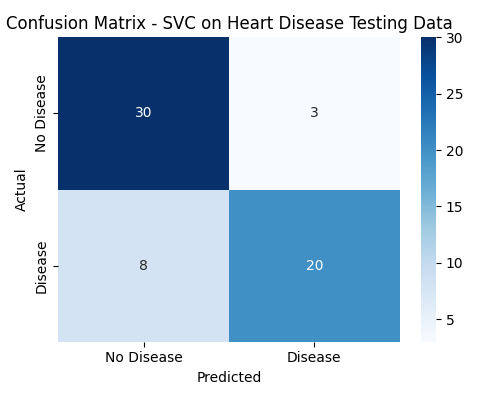

In [18]:
"""
Purpose of this section:
-------------------------
Accuracy alone can hide important mistakes. For a medical-style task:
- Precision: of the patients predicted "Heart Disease", how many really have it?
- Recall: of the patients who really have it, how many did the model catch?
  (Missing a sick patient - a false negative - is the more serious error.)
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [19]:
"""
Purpose of this section:
-------------------------
Take the four inputs of a new patient. To run interactively, replace the four
demo lines below with:

    age_input = int(input("Enter Age (years): "))
    sex_input = input("Enter Sex (Male, Female): ").strip()
    chestpain_input = input("Enter ChestPain (Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic): ").strip()
    maxhr_input = int(input("Enter MaxHeartRate (beats per minute): "))
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
age_input = 58
sex_input = "Male"
chestpain_input = "Asymptomatic"
maxhr_input = 110

print(f"Age: {age_input}, Sex: {sex_input}, ChestPain: {chestpain_input}, MaxHeartRate: {maxhr_input}")

Age: 58, Sex: Male, ChestPain: Asymptomatic, MaxHeartRate: 110


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [20]:
user_input = pd.DataFrame({
    "Age": [age_input],
    "Sex": [sex_input],
    "ChestPain": [chestpain_input],
    "MaxHeartRate": [maxhr_input],
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   Age   Sex     ChestPain  MaxHeartRate
0   58  Male  Asymptomatic           110


### Step 8.3: Label Encoding and Scaling of Feature Vector (Exactly Same as Training Data)

In [21]:
"""
Purpose of this section:
-------------------------
Encode the text inputs with the trained LabelEncoders, then scale the whole
vector with the saved scaler - the same two transformations the training data
went through.
"""

unseen_data_features = user_input.copy()
unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)

unseen_data_scaled = loaded_scaler.transform(unseen_data_features)
print("\nUser Input Encoded + Scaled Feature Vector:")
print("===========================================\n")
print(np.round(unseen_data_scaled, 3))



User Input Encoded Feature Vector:

   Age  Sex  ChestPain  MaxHeartRate
0   58    1          0           110

User Input Encoded + Scaled Feature Vector:

[[ 0.382  0.716 -0.886 -1.668]]


### Step 8.4: Load the Saved Model

In [22]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Feature Vector of the unseen instance and return Prediction to the User

In [23]:
"""
Purpose of this section:
-------------------------
Use the trained SVC to predict whether the new patient has heart disease.
"""

predicted_heart_disease = model.predict(unseen_data_scaled)

if predicted_heart_disease[0] == 1:
    prediction = "HEART DISEASE"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [24]:
"""
Purpose of this section:
-------------------------
Step 9.1: ILLUSTRATIVE example of the feedback a domain expert (a doctor)
and a tester might give. This is a worked example for the notebook, not
feedback from real people.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Doctor) - example", "Student Tester - example", "Student Tester - example"],
    "Case": [
        "Male, asymptomatic chest pain, low max heart rate -> predicted HEART DISEASE",
        "Female, typical angina, high max heart rate -> predicted NO HEART DISEASE",
        "Any patient with a missed disease case (false negative)",
    ],
    "Feedback": [
        "Consistent with clinical experience: asymptomatic presentation and poor exercise capacity are warning signs.",
        "Plausible, but typical angina should not be dismissed by a model that only sees 4 attributes.",
        "Missing a sick patient is the costliest error; recall for the disease class matters more than raw accuracy.",
    ],
})
print(example_feedback.to_string(index=False))

                        Reviewer                                                                         Case                                                                                                     Feedback
Domain Expert (Doctor) - example Male, asymptomatic chest pain, low max heart rate -> predicted HEART DISEASE Consistent with clinical experience: asymptomatic presentation and poor exercise capacity are warning signs.
        Student Tester - example    Female, typical angina, high max heart rate -> predicted NO HEART DISEASE                Plausible, but typical angina should not be dismissed by a model that only sees 4 attributes.
        Student Tester - example                      Any patient with a missed disease case (false negative)  Missing a sick patient is the costliest error; recall for the disease class matters more than raw accuracy.


#### Step 9.2: Make a List of Potential Improvements

In [25]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Use more attributes (e.g. blood pressure, cholesterol, ST depression, number of vessels) - the 4-attribute limit of this assignment caps the achievable accuracy",
    "Add the other three UCI subsets (Hungarian, Switzerland, VA Long Beach) to get more than 303 patients",
    "Use cross-validation instead of a single 80/20 split, since the test set is only about 60 patients",
    "Tune the SVC (C, gamma, kernel) and compare other models (Logistic Regression, Random Forest, Gradient Boosting)",
    "Prefer a higher recall for the disease class, e.g. by class weighting, since missing a sick patient is worse than a false alarm",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (e.g. blood pressure, cholesterol, ST depression, number of vessels) - the 4-attribute limit of this assignment caps the achievable accuracy
2. Add the other three UCI subsets (Hungarian, Switzerland, VA Long Beach) to get more than 303 patients
3. Use cross-validation instead of a single 80/20 split, since the test set is only about 60 patients
4. Tune the SVC (C, gamma, kernel) and compare other models (Logistic Regression, Random Forest, Gradient Boosting)
5. Prefer a higher recall for the disease class, e.g. by class weighting, since missing a sick patient is worse than a false alarm


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain with the improvements above and re-run Steps 6-7 to confirm the
metrics improve before replacing the deployed model.
"""

print("Next version: retrain with more attributes and data, tune the SVC with cross-validation, "
      "re-evaluate (especially recall), then replace heart_svc_trained_model.pkl")

Next version: retrain with more attributes and data, tune the SVC with cross-validation, re-evaluate (especially recall), then replace heart_svc_trained_model.pkl


## Step 10: Deploy Your Model as a Public Web App

So far the model only runs inside Jupyter on your computer. This step turns it into a **live website** that anyone can open in a browser.

#### Step 10.1: Files needed in the GitHub repository
Put these files together in one folder / repository:

| File | Purpose |
| --- | --- |
| `app.py` | The Streamlit web app (loads the model and scaler, shows the input form) |
| `heart_svc_trained_model.pkl` | The trained SVC from Step 6.5 |
| `heart_scaler.pkl` | The trained scaler from Step 6.3 |
| `requirements.txt` | Packages Streamlit Cloud must install |
| `Heart_Disease_Prediction.ipynb` | This notebook (optional but recommended) |

#### Step 10.2: Create a GitHub repository
1. Sign in at https://github.com, click **+ -> New repository**, name it (e.g. `heart-disease-app`), keep it **Public**, click **Create repository**.
2. Click **Add file -> Upload files**, drag in the files above and **Commit changes**.

#### Step 10.3: The web app (`app.py`)
`app.py` does the same thing as Step 8: it recreates the LabelEncoders from the same fixed category lists, collects the four inputs with Streamlit widgets (`st.number_input`, `st.selectbox`), encodes and scales them, calls `model.predict(...)` when the button is clicked and shows the result.

#### Step 10.4: Streamlit Community Cloud account
Go to https://share.streamlit.io and **Sign in with GitHub**.

#### Step 10.5: Deploy
1. Click **Create app -> Deploy a public app from GitHub**.
2. Repository: `<your-username>/heart-disease-app`, Branch: `main`, Main file path: `app.py`.
3. Click **Deploy**. After a minute or two you get a public link like `https://<something>.streamlit.app`.

#### Step 10.6: Troubleshooting
- **`ModuleNotFoundError` / install fails:** open **Settings -> General -> Python version** in the Streamlit Cloud dashboard and pick **3.11** or **3.12**, then save.
- **Version warning or error when loading the `.pkl` files:** the `scikit-learn` version in `requirements.txt` must be the same one that created the pkl files. Check with `pip show scikit-learn` on your computer.
- **`FileNotFoundError` for a `.pkl`:** make sure both pkl files are uploaded in the same folder as `app.py`.
- **App stuck on "in the oven":** click **Manage app** (bottom-right) to read the build log, fix the error, then reboot the app.

#### Step 10.7: Share Your Live Link
Paste the final link at the **very top of this notebook** (the assignment requires it) and in your GitHub `README.md`.

---

## Conclusion
This notebook built an end-to-end heart disease prediction system on the UCI Cleveland data using only four input attributes (Age, Sex, ChestPain, MaxHeartRate). The Support Vector Classifier reached an accuracy of **0.82** on the held-out test set (precision 0.87, recall 0.71, F1 0.78 for the heart-disease class; see Step 7.5). Feature scaling was an important step: without it the same model scored noticeably lower, because the large-range numeric attributes dominated the distance calculations. The test set is small (about 60 patients), so these numbers are only indicative. Step 9 lists improvements, such as using more attributes and data and prioritising recall, and Step 10 deploys the model as a public Streamlit web app. The system is for learning purposes only and is not a medical diagnosis tool.